# OCV-Verlaeufe und OCV-Ableitungen

Dieses Notebook liest `OCV_Plotdaten.xlsx` und `OCV_Ableitung.xlsx` ein. Es erzeugt beim Ausfuehren untereinander angeordnete Matplotlib-Abbildungen, durch die in Jupyter gescrollt werden kann.

Jede Abbildung ist auf genau einen Datentyp (`Formierung`, `Lebensdauer` oder `Lebensdauertest`) beschraenkt. Die Einzelzellen werden als blasse Linien und ihr Mittelwert als dicke Linie dargestellt.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd()
if not (ROOT / 'data').is_dir():
    ROOT = Path.cwd().parent
OCV_FILE = ROOT / 'data' / 'output' / 'OCV_Plotdaten.xlsx'
DERIVATIVE_FILE = ROOT / 'data' / 'output' / 'OCV_Ableitung.xlsx'

plt.style.use('seaborn-v0_8-whitegrid')
try:
    plt.rcParams.update({'font.family': 'Times New Roman'})
except Exception:
    plt.rcParams.update({'font.family': 'DejaVu Serif'})
plt.rcParams.update({
    'axes.formatter.use_locale': False,
    'figure.dpi': 110,
    'savefig.dpi': 300,
})
german_number = FuncFormatter(lambda value, _: f'{value:g}'.replace('.', ','))
print(f'OCV-Datei: {OCV_FILE}')
print(f'Ableitungsdatei: {DERIVATIVE_FILE}')

OCV-Datei: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\OCV_Plotdaten.xlsx
Ableitungsdatei: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\OCV_Ableitung.xlsx


In [2]:
def read_workbook(path):
    if not path.is_file():
        raise FileNotFoundError(path)
    return pd.read_excel(path, sheet_name=None, header=[0, 1], engine='openpyxl')

def clean_title(value):
    text = str(value).replace('_', ' ')
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def data_type(title):
    lowered = title.casefold()
    if 'formierung' in lowered:
        return 'Formierung'
    if 'lebensdauertest' in lowered:
        return 'Lebensdauertest'
    if 'lebensdauer' in lowered:
        return 'Lebensdauer'
    return 'Sonstige'

STANDARD_DURATIONS = (1, 24, 48, 168)

def duration_label(time_values):
    maximum = float(np.nanmax(time_values))
    closest = min(STANDARD_DURATIONS, key=lambda duration: abs(maximum - duration))
    tolerance = max(0.1, closest * 0.02)
    if abs(maximum - closest) <= tolerance:
        return f'{closest} h'
    return f'{maximum:g} h'

def group_definitions():
    return {
        'Knopfzellen - 5 µm': ['5um_1h', '5um_24h', '5um_48h', '5um_168h'],
        'Knopfzellen - 10 µm': ['10um_1h', '10um_24h', '10um_48h', '10um_168h'],
        'Knopfzellen - Referenz': ['Ref_1h'],
        'Pouchzellen - 10 µm': ['Pouch_10um_48h_0b', 'Pouch_10um_48h_1b', 'Pouch_10um_48h_2b', 'Pouch_10um_48h_3b'],
        'Pouchzellen - Referenz': ['Pouch_Ref_48h'],
        'Sonstige PreLi-Daten': ['Other'],
    }

def extract_series(frame, sheet_name, value_label):
    result = []
    if not isinstance(frame.columns, pd.MultiIndex):
        return result
    for index in range(0, len(frame.columns) - 1):
        title, first_header = frame.columns[index]
        _, second_header = frame.columns[index + 1]
        first_header = str(first_header).strip()
        second_header = str(second_header).strip()
        if first_header != 'Zeit [h]' or second_header != value_label:
            continue
        if str(title).strip() == 'nan' or str(title).strip().casefold().startswith('durchschnitt'):
            continue
        time = pd.to_numeric(frame.iloc[:, index], errors='coerce')
        value = pd.to_numeric(frame.iloc[:, index + 1], errors='coerce')
        valid = time.notna() & value.notna()
        if valid.any():
            result.append({
                'title': clean_title(title),
                'type': data_type(str(title)),
                'duration': duration_label(time[valid].to_numpy(float)),
                'time': time[valid].to_numpy(float),
                'value': value[valid].to_numpy(float),
            })
    return result

ocv_workbook = read_workbook(OCV_FILE)
derivative_workbook = read_workbook(DERIVATIVE_FILE)
print('OCV-Sheets:', ', '.join(ocv_workbook))
print('Ableitungs-Sheets:', ', '.join(derivative_workbook))

OCV-Sheets: Ref_1h, 5um_1h, 5um_24h, 5um_48h, 5um_168h, 10um_1h, 10um_24h, 10um_48h, 10um_168h, 5um_48h_35C, 10um_48h_35C, Pouch_Ref_48h, Pouch_10um_48h_0b, Pouch_10um_48h_1b, Pouch_10um_48h_2b, Pouch_10um_48h_3b, Other
Ableitungs-Sheets: Ref_1h, 5um_1h, 5um_24h, 5um_48h, 5um_168h, 10um_1h, 10um_24h, 10um_48h, 10um_168h, 5um_48h_35C, 10um_48h_35C, Pouch_Ref_48h, Pouch_10um_48h_0b, Pouch_10um_48h_1b, Pouch_10um_48h_2b, Pouch_10um_48h_3b, Other


Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Knopfzellen_-_5_m_Formierung.svg


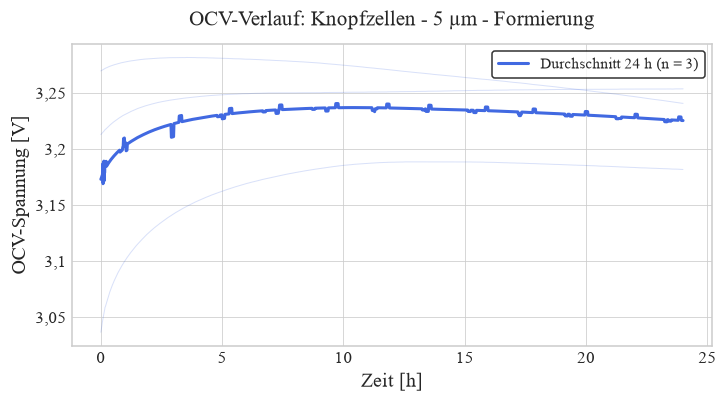

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Knopfzellen_-_5_m_Lebensdauer.svg


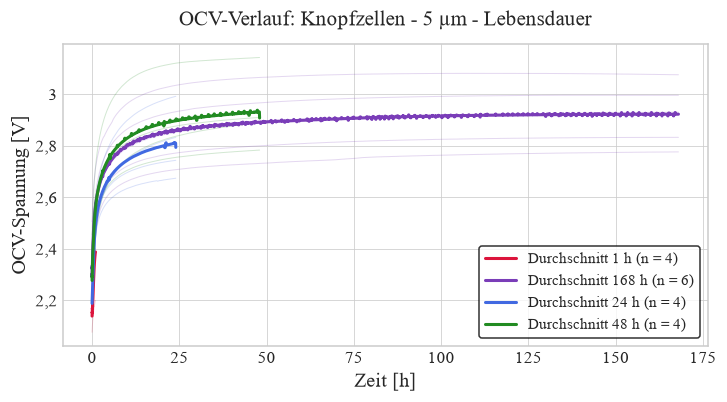

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Knopfzellen_-_10_m_Lebensdauer.svg


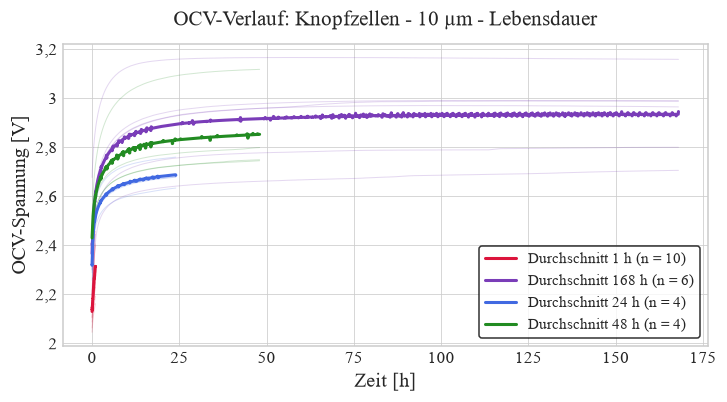

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Knopfzellen_-_10_m_Lebensdauertest.svg


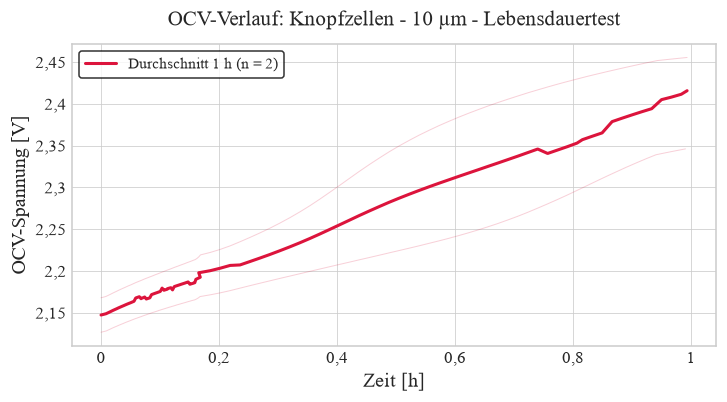

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Knopfzellen_-_Referenz_Formierung.svg


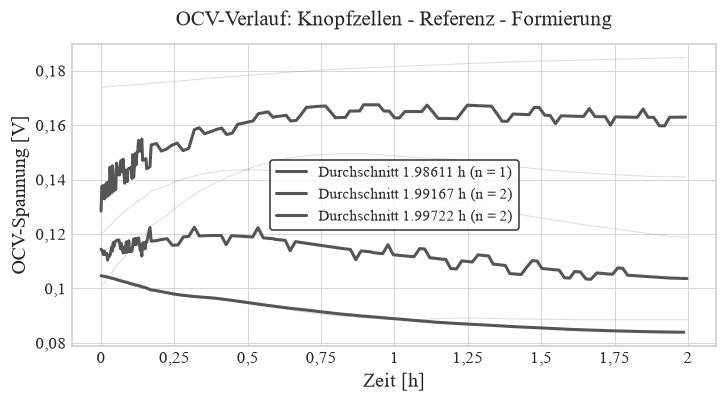

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Knopfzellen_-_Referenz_Lebensdauer.svg


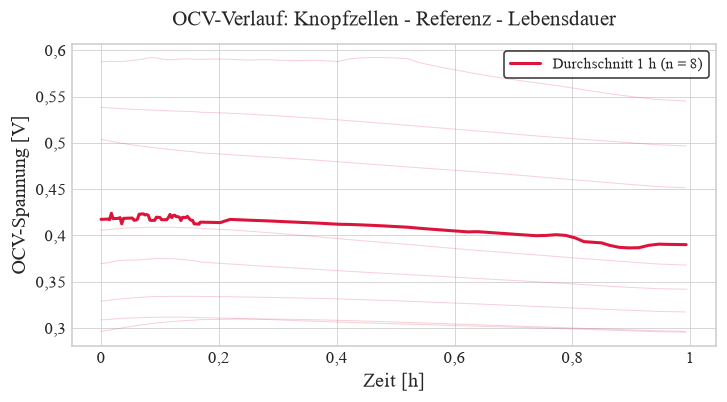

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Knopfzellen_-_Referenz_Lebensdauertest.svg


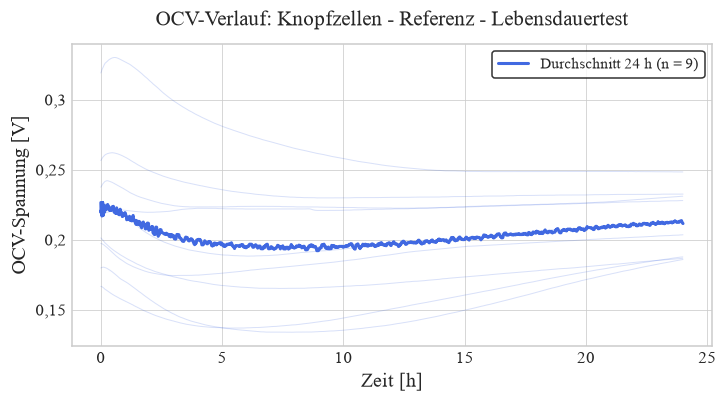

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Pouchzellen_-_10_m_Formierung.svg


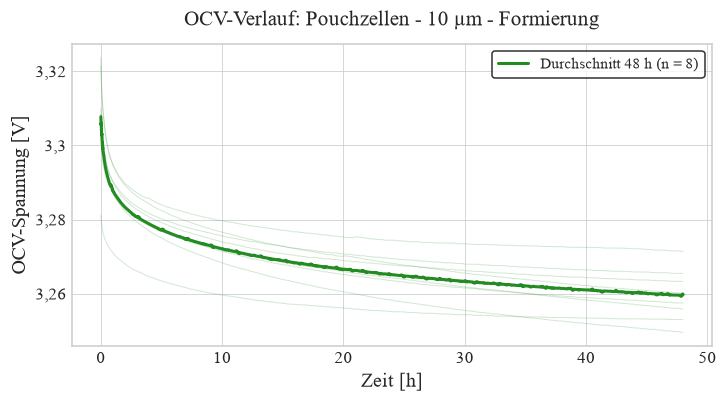

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Pouchzellen_-_10_m_Lebensdauer.svg


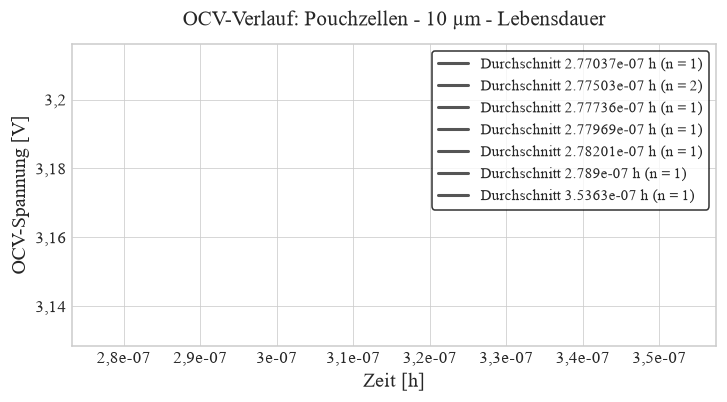

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Pouchzellen_-_Referenz_Formierung.svg


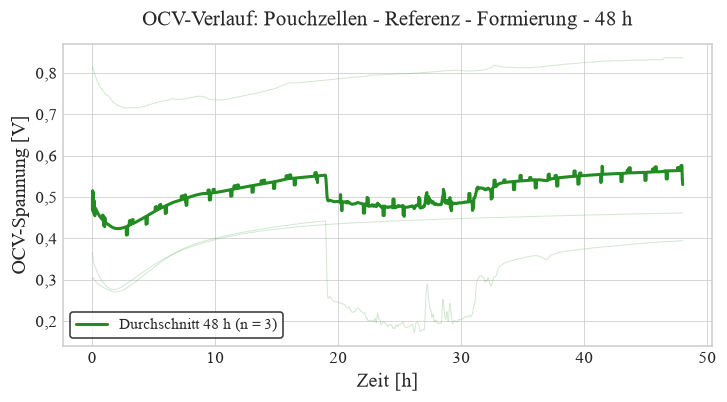

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Pouchzellen_-_Referenz_Lebensdauer.svg


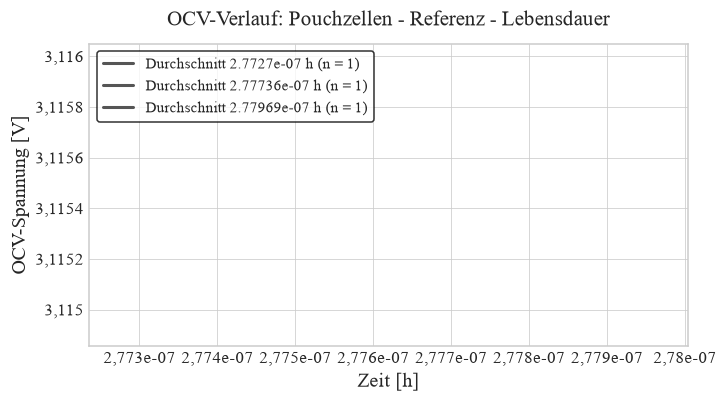

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Sonstige_PreLi-Daten_Lebensdauertest.svg


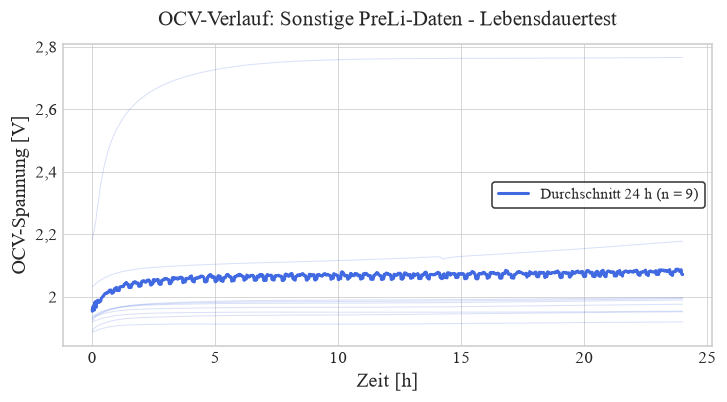

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\OCV\Sonstige_PreLi-Daten_Sonstige.svg


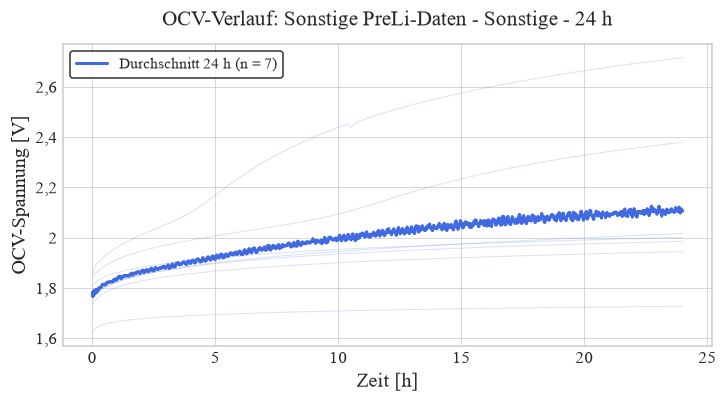

In [3]:
PLOT_DIR = ROOT / 'data' / 'output' / 'ocv_plots'
OCV_PLOT_DIR = PLOT_DIR / 'OCV'
DERIVATIVE_PLOT_DIR = PLOT_DIR / 'Ableitung'
OCV_PLOT_DIR.mkdir(parents=True, exist_ok=True)
DERIVATIVE_PLOT_DIR.mkdir(parents=True, exist_ok=True)

def clear_generated_plots(directory):
    for path in directory.glob('*.svg'):
        path.unlink()

clear_generated_plots(OCV_PLOT_DIR)
clear_generated_plots(DERIVATIVE_PLOT_DIR)
SMOOTHING_WINDOW = 7

COLORS = {
    '1 h': '#DC143C',
    '24 h': '#4169E1',
    '48 h': '#228B22',
    '168 h': '#7A3DB8',
    'ohne Dauerangabe': '#555555',
}

def smooth(values, window=SMOOTHING_WINDOW):
    if len(values) < 3:
        return values
    return pd.Series(values).rolling(window=window, center=True, min_periods=1).mean().to_numpy()

def average_by_time_bins(series_list):
    bins = {}
    for series in series_list:
        for time, value in zip(series['time'], series['value']):
            seconds = time * 3600.0
            interval = 10.0 if seconds <= 600.5 else 60.0
            key = (interval, round(seconds / interval))
            bins.setdefault(key, []).append((time, value))
    if not bins:
        return np.array([]), np.array([])
    points = [
        (np.mean([item[0] for item in values]), np.mean([item[1] for item in values]))
        for _, values in sorted(bins.items(), key=lambda item: item[0][0] * item[0][1])
    ]
    return np.array([point[0] for point in points]), smooth(np.array([point[1] for point in points]))

def plot_group(workbook, sheet_names, value_label, ylabel, title, output_path, duration=None, data_kind=None):
    series = []
    for sheet_name in sheet_names:
        if sheet_name in workbook:
            sheet_series = extract_series(workbook[sheet_name], sheet_name, value_label)
            if duration is not None:
                sheet_series = [item for item in sheet_series if item['duration'] == duration]
            if data_kind is not None:
                sheet_series = [item for item in sheet_series if item['type'] == data_kind]
            series.extend(sheet_series)
    if not series:
        return
    figure, axis = plt.subplots(figsize=(16.5 / 2.54, 9 / 2.54), constrained_layout=True)
    by_duration = {}
    for item in series:
        color = COLORS.get(item['duration'], '#555555')
        axis.plot(item['time'], smooth(item['value']), color=color, alpha=0.20, linewidth=0.65)
        by_duration.setdefault(item['duration'], []).append(item)
    for duration_name, items in sorted(by_duration.items(), key=lambda pair: pair[0]):
        time, value = average_by_time_bins(items)
        if len(time):
            axis.plot(time, value, color=COLORS.get(duration_name, '#555555'), linewidth=2.0, label=f'Durchschnitt {duration_name} (n = {len(items)})')
    duration_text = f' - {duration}' if duration else ''
    axis.set_title(f'{title}{duration_text}', fontsize=14, pad=12)
    axis.set_xlabel('Zeit [h]', fontsize=13)
    axis.set_ylabel(ylabel, fontsize=13)
    axis.xaxis.set_major_formatter(german_number)
    axis.yaxis.set_major_formatter(german_number)
    axis.tick_params(axis='both', labelsize=11)
    axis.grid(True, linewidth=0.5, alpha=1.0)
    axis.legend(loc='best', frameon=True, facecolor='white', edgecolor='black', fontsize=10)
    figure.savefig(output_path, format='svg', bbox_inches='tight')
    print(f'Gespeichert: {output_path}')
    plt.show()
    plt.close(figure)


groups = group_definitions()
PLOT_DURATION_FILTERS = {
    ('Pouchzellen - Referenz', 'Formierung'): '48 h',
    ('Sonstige PreLi-Daten', 'Sonstige'): '24 h',
}
for title, sheets in groups.items():
    data_kinds = sorted({
        item['type']
        for sheet_name in sheets
        if sheet_name in ocv_workbook
        for item in extract_series(ocv_workbook[sheet_name], sheet_name, 'Spannung [V]')
    })
    for data_kind in data_kinds:
        duration = PLOT_DURATION_FILTERS.get((title, data_kind))
        filename = re.sub(r'[^A-Za-z0-9_-]+', '_', f'{title}_{data_kind}').strip('_') + '.svg'
        plot_group(ocv_workbook, sheets, 'Spannung [V]', 'OCV-Spannung [V]', f'OCV-Verlauf: {title} - {data_kind}', OCV_PLOT_DIR / filename, duration=duration, data_kind=data_kind)

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_5_m_Formierung_24_h.svg


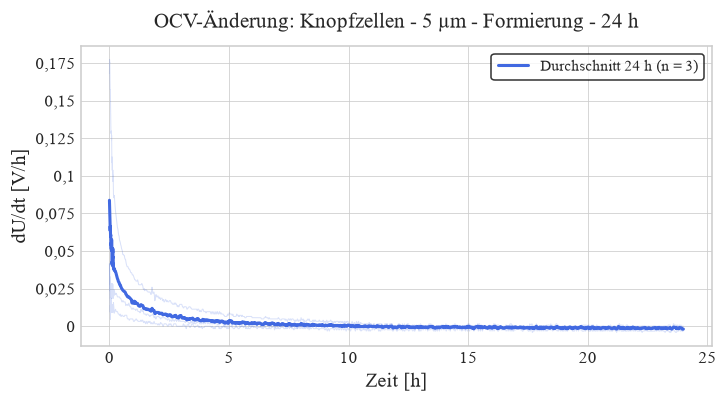

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_5_m_Lebensdauer_1_h.svg


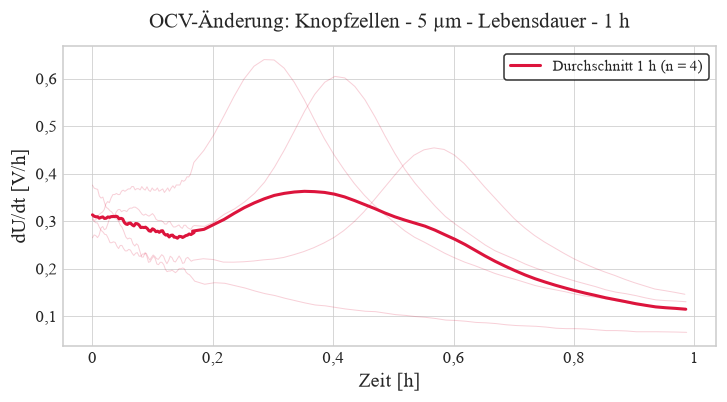

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_5_m_Lebensdauer_24_h.svg


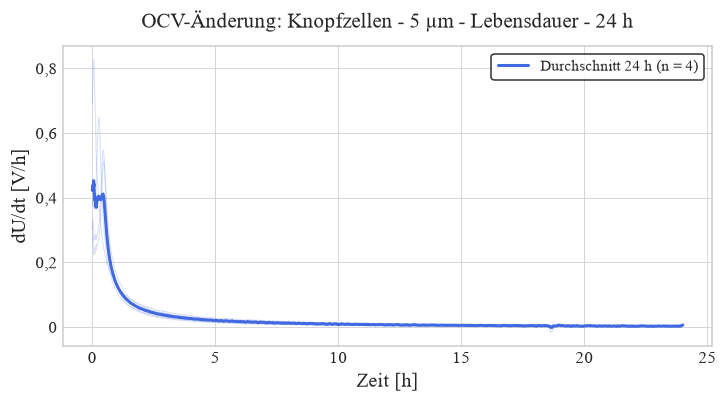

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_5_m_Lebensdauer_48_h.svg


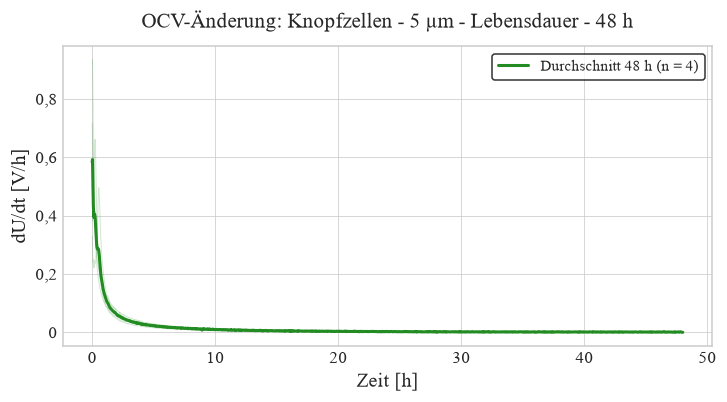

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_5_m_Lebensdauer_168_h.svg


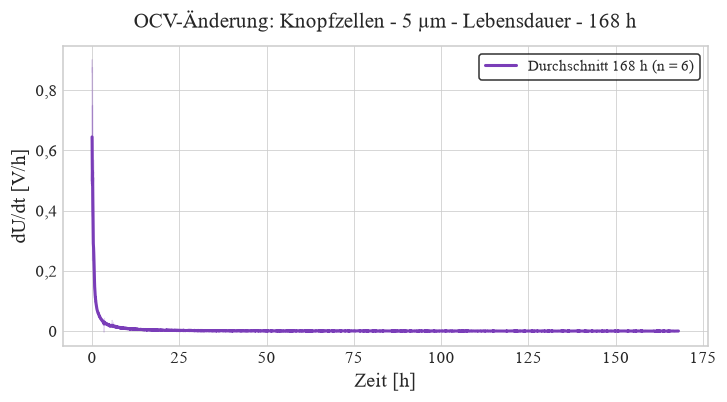

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_10_m_Lebensdauer_1_h.svg


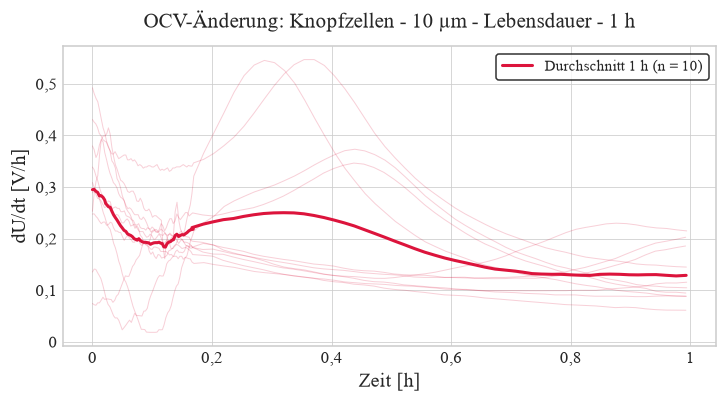

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_10_m_Lebensdauer_24_h.svg


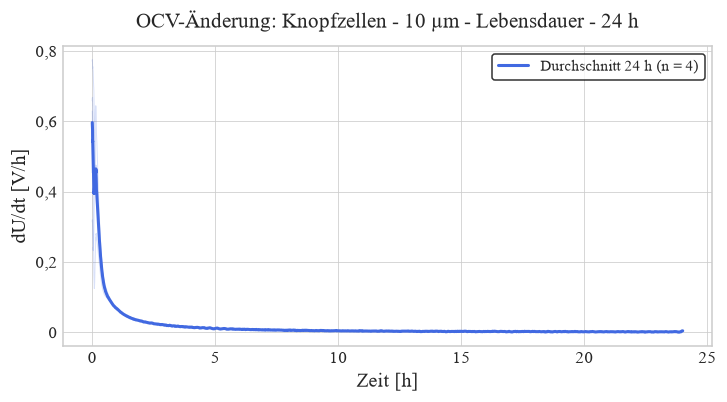

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_10_m_Lebensdauer_48_h.svg


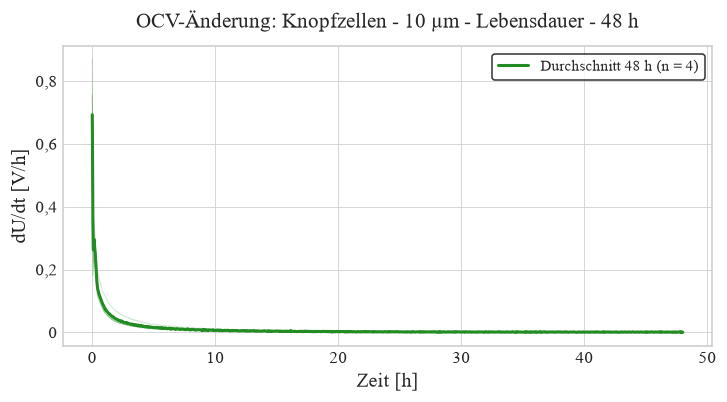

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_10_m_Lebensdauer_168_h.svg


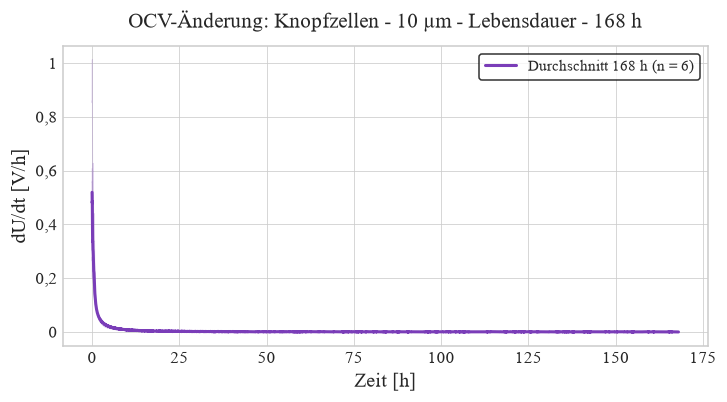

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_10_m_Lebensdauertest_1_h.svg


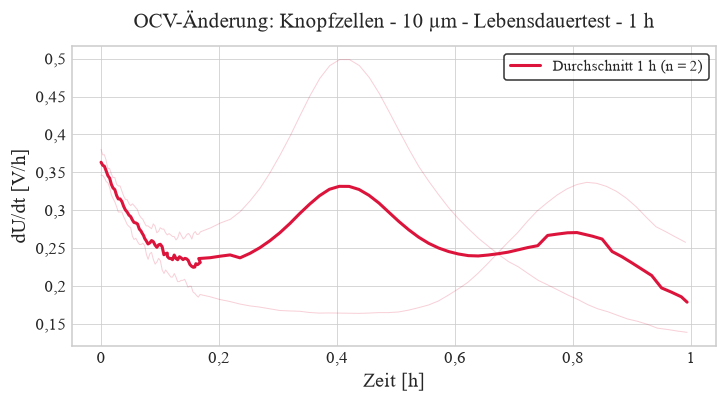

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_Referenz_Formierung_1_98611_h.svg


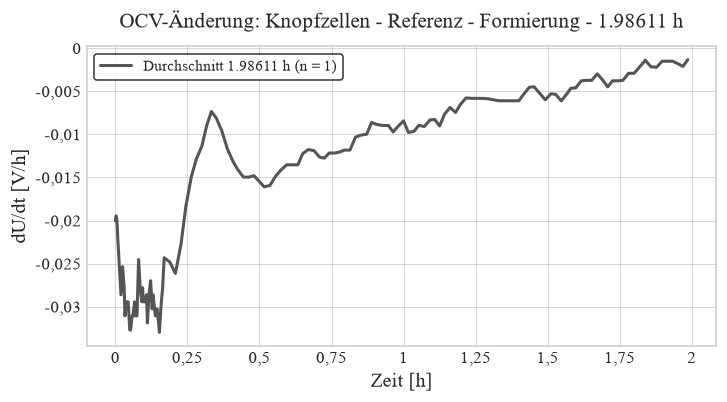

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_Referenz_Formierung_1_99167_h.svg


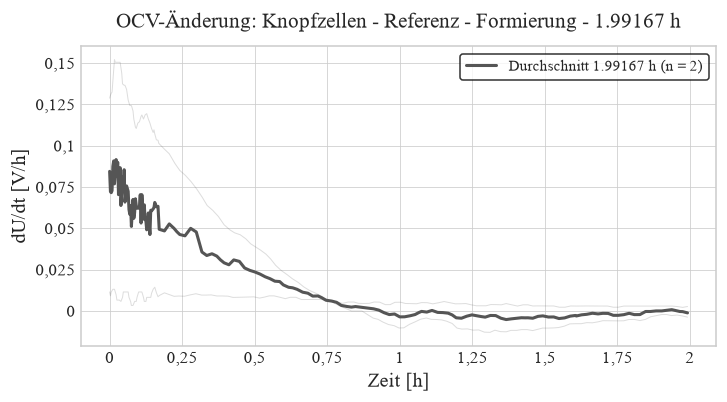

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_Referenz_Formierung_1_99722_h.svg


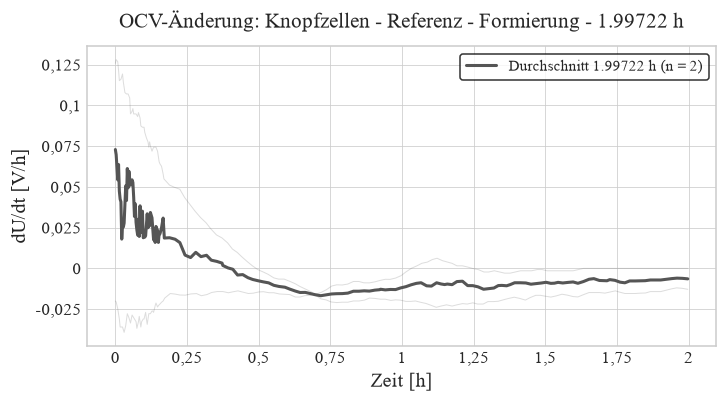

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Knopfzellen_-_Referenz_Lebensdauer_1_h.svg


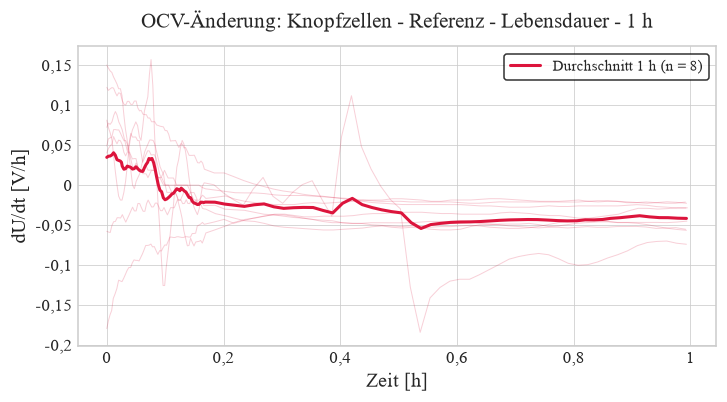

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Pouchzellen_-_10_m_Formierung_48_h.svg


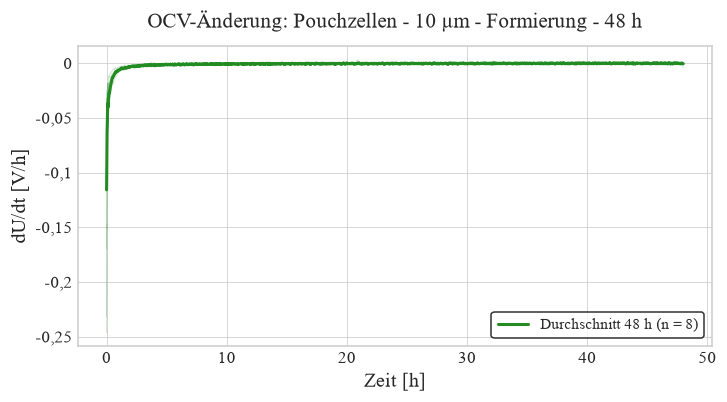

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Pouchzellen_-_Referenz_Formierung_0_0116967_h.svg


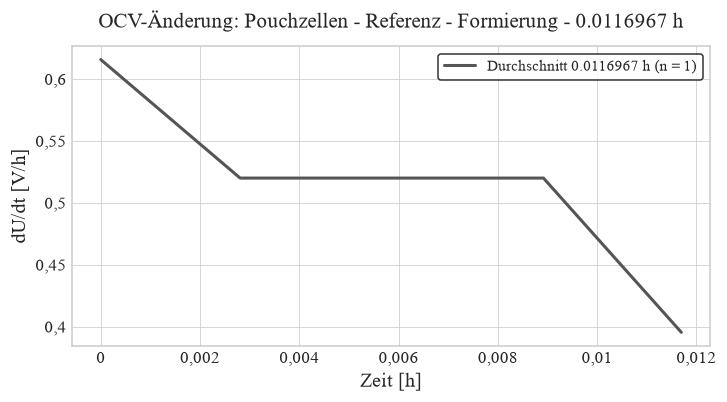

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Pouchzellen_-_Referenz_Formierung_1_5142_h.svg


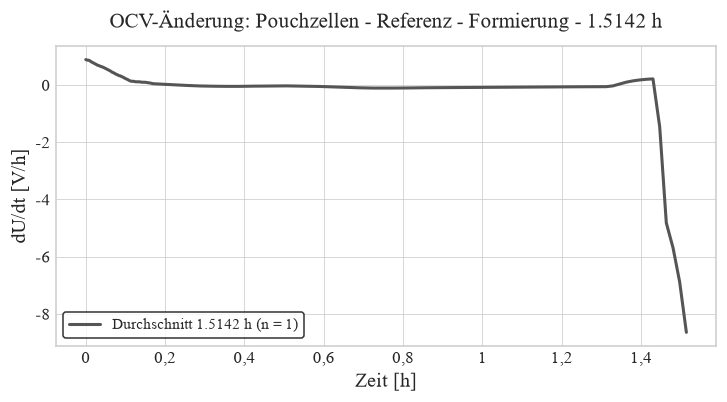

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Pouchzellen_-_Referenz_Formierung_48_h.svg


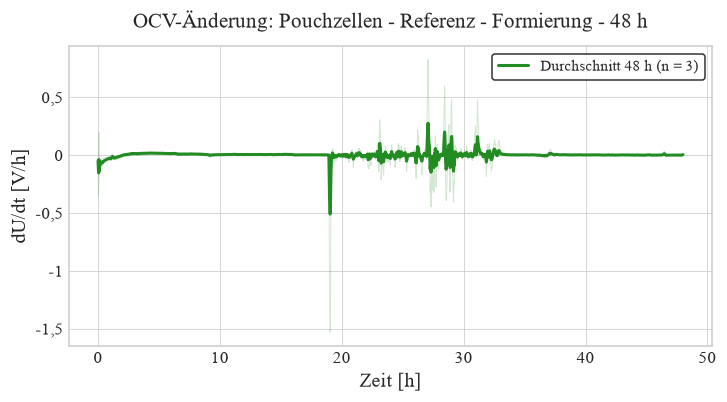

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Sonstige_PreLi-Daten_Sonstige_0_166701_h.svg


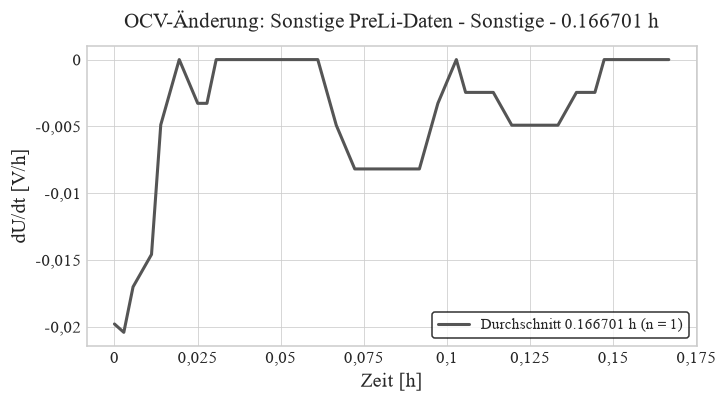

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Sonstige_PreLi-Daten_Sonstige_0_166702_h.svg


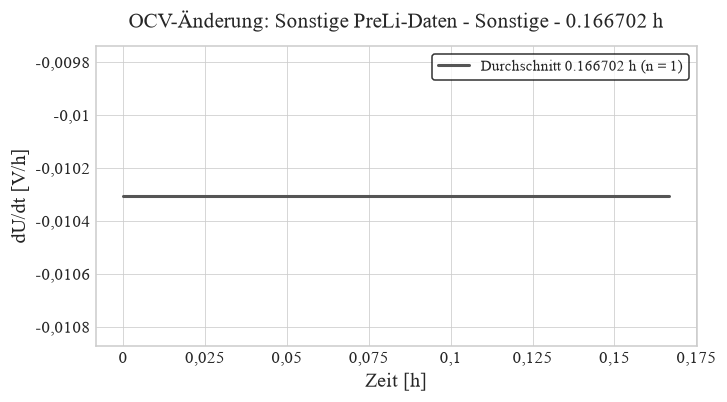

Gespeichert: D:\HiWi\Lebensdauer_Auswertung_Batterie\data\output\ocv_plots\Ableitung\Sonstige_PreLi-Daten_Sonstige_24_h.svg


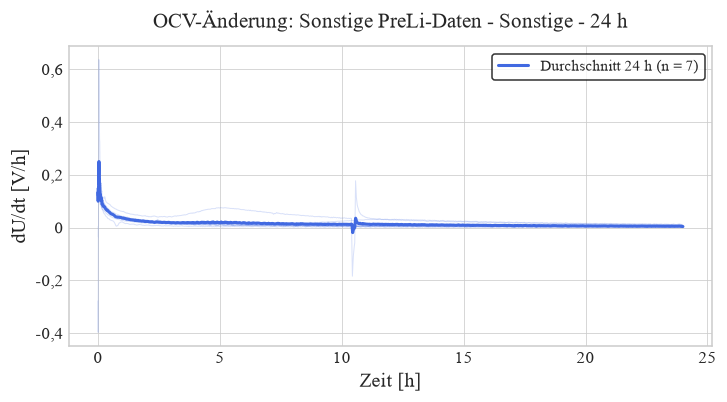

OCV-SVGs: 13
Ableitungs-SVGs: 21


In [4]:
for title, sheets in groups.items():
    series = [
        item
        for sheet_name in sheets
        if sheet_name in derivative_workbook
        for item in extract_series(derivative_workbook[sheet_name], sheet_name, 'dU/dt [V/h]')
    ]
    data_kinds = sorted({item['type'] for item in series})
    for data_kind in data_kinds:
        durations = sorted({item['duration'] for item in series if item['type'] == data_kind}, key=lambda value: (float(value.split()[0]) if value[0].isdigit() else float('inf')))
        for duration in durations:
            filename = re.sub(r'[^A-Za-z0-9_-]+', '_', f'{title}_{data_kind}_{duration}').strip('_') + '.svg'
            plot_group(derivative_workbook, sheets, 'dU/dt [V/h]', 'dU/dt [V/h]', f'OCV-Änderung: {title} - {data_kind}', DERIVATIVE_PLOT_DIR / filename, duration=duration, data_kind=data_kind)

print(f'OCV-SVGs: {len(list(OCV_PLOT_DIR.glob("*.svg")))}')
print(f'Ableitungs-SVGs: {len(list(DERIVATIVE_PLOT_DIR.glob("*.svg")))}')

## Interpretation

Die farbigen dicken Kurven sind die Mittelwerte je PrÃ¤lithiierungsdauer. Die blassen Linien zeigen die einzelnen Batteriezellen. Der Mittelwert wird in denselben zeitbasierten 10-Sekunden-Fenstern bis 10 Minuten und danach in 60-Sekunden-Fenstern gebildet wie bei der Plotdatenreduktion.

Falls `openpyxl` fehlt, kann es einmalig mit `python -m pip install openpyxl` installiert werden. FÃ¼r eine OriginPro-Weiterverarbeitung bleiben die Excel-Dateien unverÃ¤ndert; dieses Notebook verwendet sie nur als Eingabe.